# 🌌 APP V3 — Detecção de EPBs com Arquitetura em Cascata

Carrega automaticamente a versão mais recente do modelo treinado (**v4.0**) e processa imagens individuais ou sequências temporais completas com **Controle de Qualidade de Céu (QC)**.

### ✨ Funcionalidades:
1. **Predição em Cascata:** Distingue *Céu Limpo com EPB*, *Céu Limpo Quieto* e *Céu Nublado / Obstruído*.
2. **Explicabilidade Segura:** Mapas de importância 2DPCA e atribuição SHAP ativados apenas para imagens de céu válido.
3. **Análise Temporal Completa:** Linha do tempo com 3 estados visuais ao longo de noites inteiras de observação.

In [1]:
from PIL import Image
import numpy as np
from pathlib import Path

from epb_detection_system import (
    preprocess_epb_image,
    load_model,
    load_epb_dataset,
    explain_feature_importance_3 as explain_features,
    explain_shap_importance,
    analyze_temporal_sequence,
    analyze_critical_periods,
    assess_sky_quality,
    predict_with_qc,
)

In [2]:
# ========== CARREGAMENTO DO MODELO (auto-detecta a versão mais recente) ==========
MODEL_DIR = Path('models')
MODEL_PREFIX = 'epb_recognition_model-v'
MODEL_SUFFIX = '.pkl'

model_files = sorted(
    MODEL_DIR.glob(f'{MODEL_PREFIX}*{MODEL_SUFFIX}'),
    key=lambda p: [int(x) for x in p.stem.replace(MODEL_PREFIX, '').split('.')],
    reverse=True,
)

if not model_files:
    raise FileNotFoundError(
        f"Nenhum modelo encontrado em '{MODEL_DIR}'. "
        "Execute o notebook de treinamento primeiro."
    )

model_path = model_files[0]  # versão mais recente
print(f"📦 Carregando modelo: {model_path.name}")

model_data = load_model(str(model_path))
system = model_data.system
target_size = model_data.target_size

print(f"   ✓ Versão: v{model_data.version}")
print(f"   ✓ Tamanho das imagens: {target_size}")
if model_data.test_metrics:
    acc = model_data.test_metrics.get('accuracy', 0)
    print(f"   ✓ Accuracy (teste): {acc:.2%}")
print("   ✓ Modelo carregado com sucesso!")

📦 Carregando modelo: epb_recognition_model-v4.0.pkl
   ✓ Versão: v4.0
   ✓ Tamanho das imagens: (64, 64)
   ✓ Accuracy (teste): 100.00%
   ✓ Modelo carregado com sucesso!


In [3]:
# ========== HELPER: carrega e pré-processa imagens de teste ==========
IMG_FOLDER = Path('img-teste')

def load_test_images(folder=IMG_FOLDER):
    """Retorna lista de paths de imagens na pasta especificada."""
    files = sorted(
        list(folder.glob('*.png')) +
        list(folder.glob('*.jpg')) +
        list(folder.glob('*.jpeg'))
    )
    if not files:
        print(f"⚠️  Nenhuma imagem encontrada em '{folder}'")
    return files

def process_image(img_path):
    """Carrega, redimensiona e pré-processa uma imagem."""
    img = Image.open(img_path).convert('L')
    img = np.array(img.resize(target_size))
    return preprocess_epb_image(img)

In [4]:
# ========== 1. PREDIÇÕES EM CASCATA COM CONTROLE DE QUALIDADE (QC) ==========
image_files = load_test_images()

if image_files:
    print("="*70)
    print(f"🔍 PREDIÇÕES EM CASCATA PARA {len(image_files)} IMAGENS (img-teste/)")
    print("="*70 + "\n")

    for img_path in image_files:
        try:
            img_raw = np.array(Image.open(img_path).convert('L'))
            res = predict_with_qc(system, img_raw, target_size=target_size)

            print(f"📸 {img_path.name}")
            print(f"   • Condição do Céu: {res.qc.condition} ({res.qc.reason})")
            print(f"   • Status:          {res.status_label}")
            if res.qc.is_valid_sky:
                print(f"   • Probabilidade EPB: {res.prob_epb*100:.2f}%")
                if res.is_reliable:
                    print(f"   • Confiança:       🟢 ALTA")
                else:
                    print(f"   • Confiança:       🟡 PARCIAL (Céu Degradado)")
            else:
                print(f"   • Diagnóstico:     ⚪ Imagem descartada pelo filtro QC (sem dados ionosféricos)")
            print()

        except Exception as e:
            print(f"❌ {img_path.name}: {e}\n")

    print("="*70)
    print("✅ PROCESSAMENTO CONCLUÍDO")
    print("="*70)

🔍 PREDIÇÕES EM CASCATA PARA 2 IMAGENS (img-teste/)

📸 O6_BJL_20250723_003008.png
   • Condição do Céu: CLEAR (Céu limpo com alta visibilidade (Estrelas: 11139, Brilho médio: 77.3))
   • Status:          Céu Limpo Sem EPB (Quieto)
   • Probabilidade EPB: 2.37%
   • Confiança:       🟢 ALTA

📸 O6_CA_20251023_001620.png
   • Condição do Céu: CLEAR (Céu limpo com alta visibilidade (Estrelas: 10133, Brilho médio: 96.1))
   • Status:          Bolha de Plasma (EPB) Detectada
   • Probabilidade EPB: 97.42%
   • Confiança:       🟢 ALTA

✅ PROCESSAMENTO CONCLUÍDO


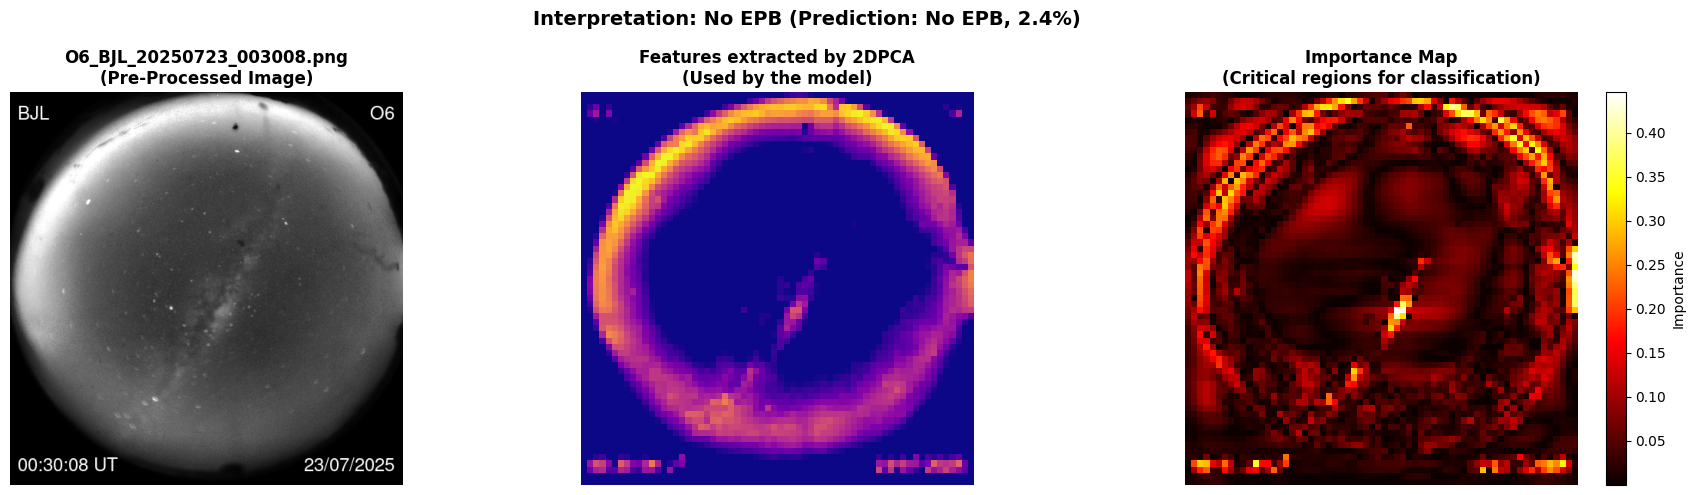

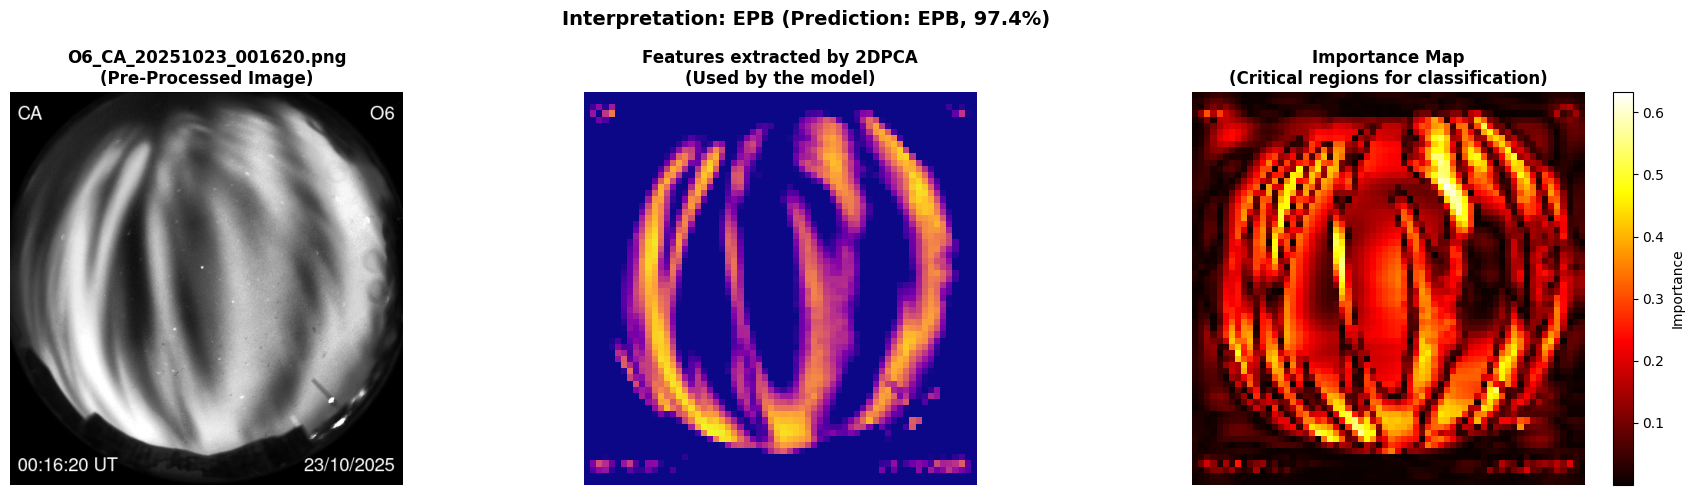

In [5]:
# ========== 2. ANÁLISE DETALHADA DE FEATURES (2DPCA) ==========
image_files = load_test_images()

for img_path in image_files:
    img_raw = np.array(Image.open(img_path).convert('L'))
    res = predict_with_qc(system, img_raw, target_size=target_size)
    
    if not res.qc.is_valid_sky:
        print(f"⏩ Pulando mapa 2DPCA para {img_path.name} (Céu nublado — sem sinal ionosférico)")
        continue
        
    img_prep = process_image(img_path)
    explain_features(system, img_prep, y_sample=res.has_epb,
                     filename=img_path.name, image_folder=str(IMG_FOLDER))

/home/ivo/miniconda3/envs/mestrado/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
TreeExplainer falhou com xgboost, tentando próximo modelo...



🔬 ANÁLISE SHAP — Importance Real para Classificação

📸 Imagem: O6_BJL_20250723_003008.png
   • True class: No EPB
   • Prediction: No EPB (2.4%)
   • Método SHAP: TreeExplainer (tree-based)

📊 SHAP contribution by quadrant:
   • Upper Left: 63.3% (↓ No EPB)
   • Upper Right: 35.1% (↑ EPB)
   • Lower Right: 1.1% (↓ No EPB)
   • Lower Left: 0.6% (↓ No EPB)

📐 Correlação |SHAP| vs. Reconstruction Error: 0.241 (Spearman)
   → Baixa correlação: SHAP e reconstrução focam em regiões distintas

💡 Interpretation:
   As regiões azuis no mapa SHAP mostram evidência de ionosfera
   quieta (ausência de estruturas irregulares).


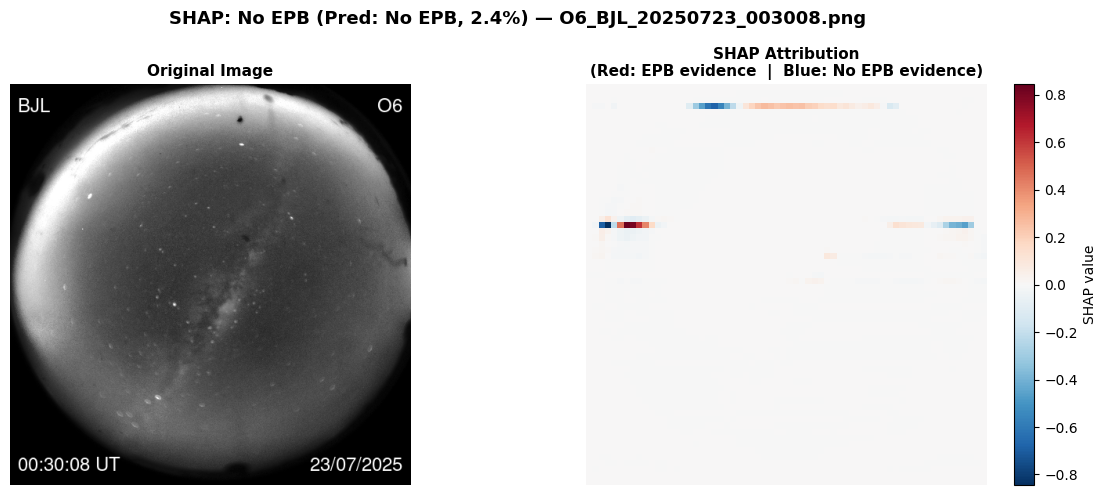

TreeExplainer falhou com xgboost, tentando próximo modelo...



🔬 ANÁLISE SHAP — Importance Real para Classificação

📸 Imagem: O6_CA_20251023_001620.png
   • True class: EPB
   • Prediction: EPB (97.4%)
   • Método SHAP: TreeExplainer (tree-based)

📊 SHAP contribution by quadrant:
   • Upper Left: 38.1% (↑ EPB)
   • Upper Right: 35.0% (↑ EPB)
   • Lower Right: 13.9% (↑ EPB)
   • Lower Left: 13.0% (↑ EPB)

📐 Correlação |SHAP| vs. Reconstruction Error: 0.346 (Spearman)
   → Baixa correlação: SHAP e reconstrução focam em regiões distintas

💡 Interpretation:
   As regiões vermelhas no mapa SHAP mostram onde o modelo
   encontra evidência de EPB (estruturas verticais, deplecções).


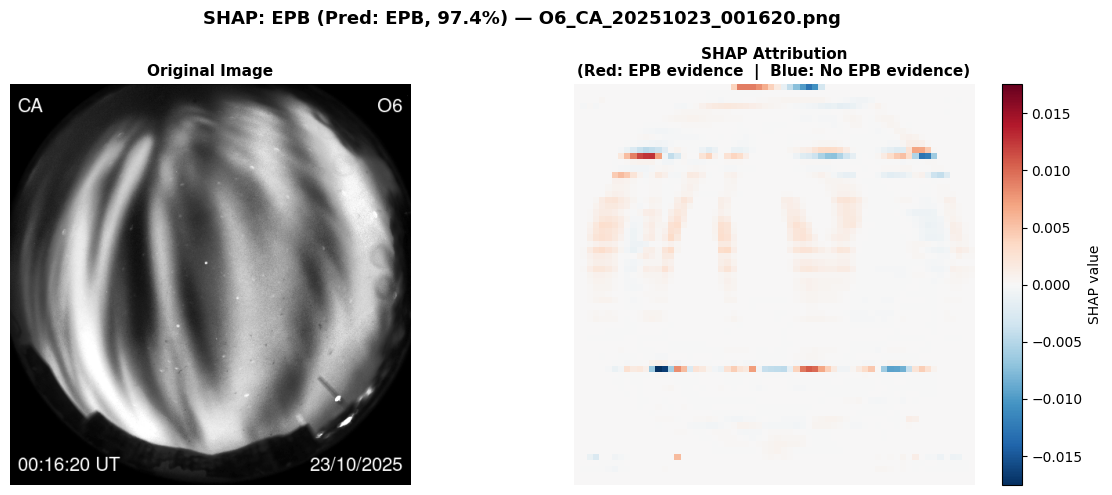

In [6]:
# ========== 3. ANÁLISE SHAP (TreeExplainer) ==========
# Carrega background de referência do dataset
X_bg, y_bg, _ = load_epb_dataset('data/all-images', 'data/epb_labels.csv',
                                 target_size=target_size, apply_preprocessing=True)
X_bg_clean = X_bg[y_bg == 0][:50]  # Amostras de céu quieto como referência

image_files = load_test_images()

for img_path in image_files:
    img_raw = np.array(Image.open(img_path).convert('L'))
    res = predict_with_qc(system, img_raw, target_size=target_size)
    
    if not res.qc.is_valid_sky:
        print(f"⏩ Pulando SHAP para {img_path.name} (Céu nublado)")
        continue
        
    img_prep = process_image(img_path)
    explain_shap_importance(
        system,
        X_sample=img_prep,
        X_background=X_bg_clean,
        y_sample=res.has_epb,
        filename=img_path.name,
        image_folder=str(IMG_FOLDER),
        method='tree'
    )

🌃 Processando sequência temporal com EPB: util/CA_20251022/processed
🕐 TEMPORAL SEQUENCE ANALYSIS OF IMAGES (Cascaded QC + 2DPCA)
📂 Folder: util/CA_20251022/processed
📸 Total images: 140
🛡️  Filtro de Qualidade de Céu (QC): Ativado



📊 Prediction summary:
   • Céu Limpo com EPB: 139 imagens (99.3%)
   • Céu Limpo Sem EPB: 0 imagens (0.0%)
   • Céu Nublado / Obstruído: 1 imagens (0.7%)
   • Average EPB probability (Céu Limpo): 91.8%

🔄 Detected transitions (1):
   • 21:18:24 - Changed to: EPB (81.5%)


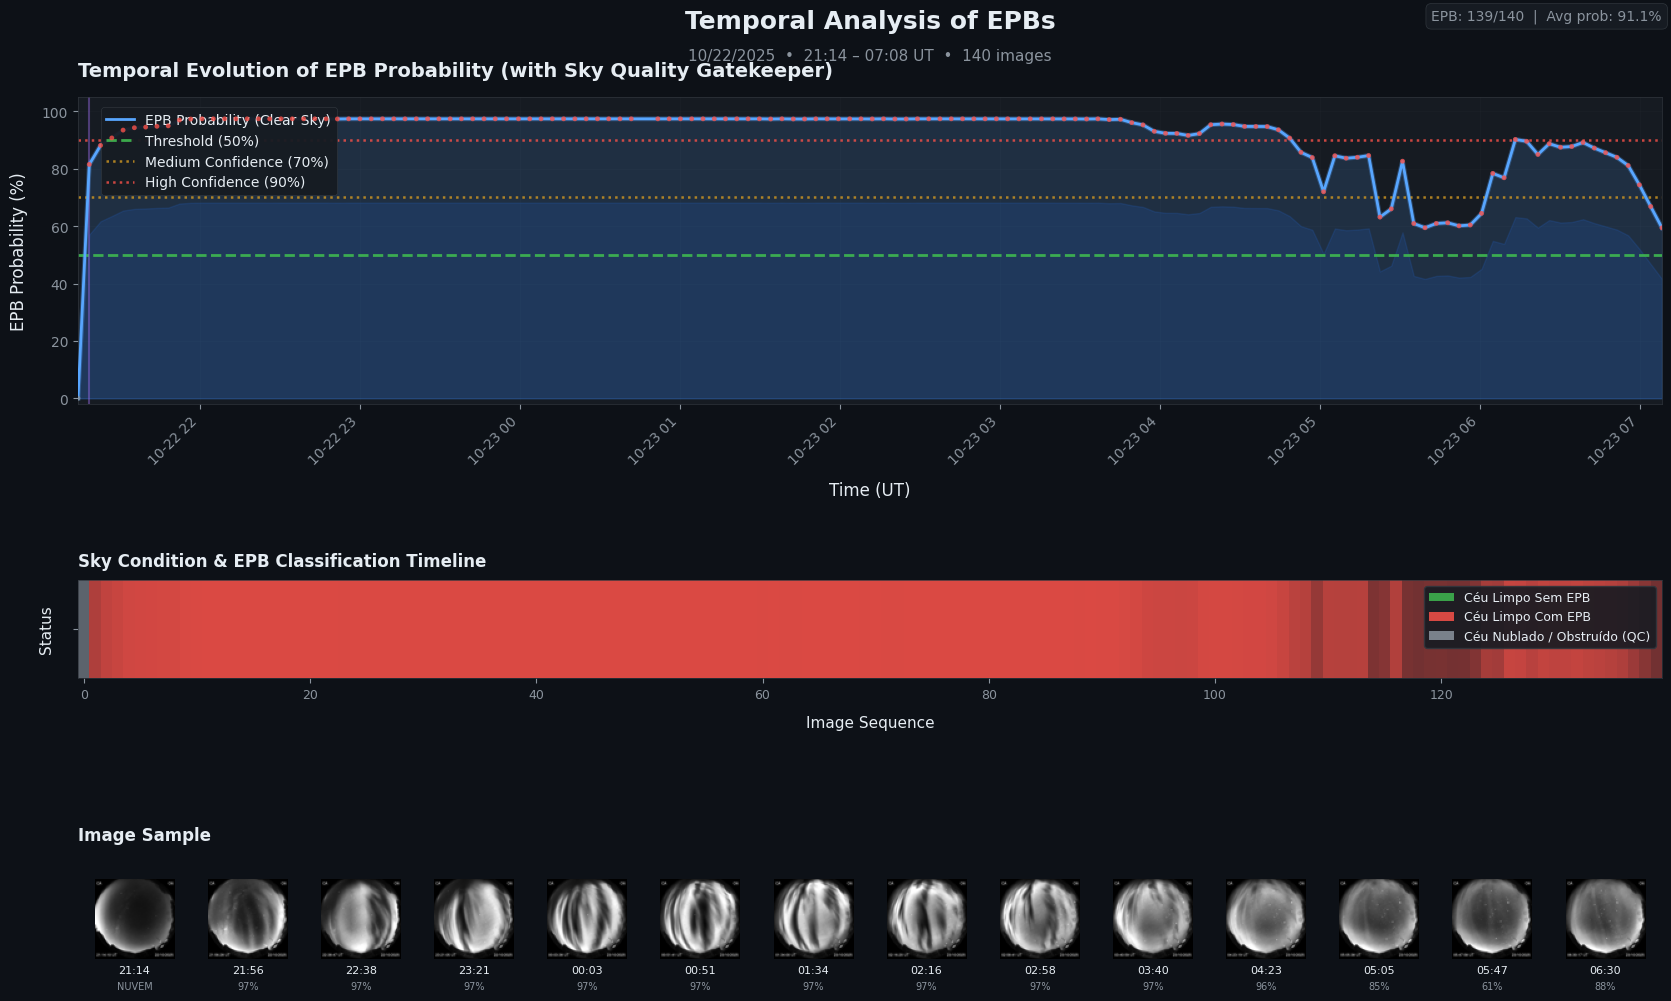


✅ TEMPORAL ANALYSIS COMPLETED


In [7]:
# ========== 4. ANÁLISE TEMPORAL (NOITE COM EPB) ==========
EPB_NIGHT_FOLDER = 'util/CA_20251022/processed'

print(f"🌃 Processando sequência temporal com EPB: {EPB_NIGHT_FOLDER}")
df_epb_night = analyze_temporal_sequence(
    system=system,
    image_folder=EPB_NIGHT_FOLDER,
    target_size=target_size,
    show_thumbnails=True,
    thumbnail_interval=10,
    use_qc=True
)

☁️ Processando sequência temporal nublada: util/CA_20260624/processed
🕐 TEMPORAL SEQUENCE ANALYSIS OF IMAGES (Cascaded QC + 2DPCA)
📂 Folder: util/CA_20260624/processed
📸 Total images: 62
🛡️  Filtro de Qualidade de Céu (QC): Ativado



📊 Prediction summary:
   • Céu Limpo com EPB: 20 imagens (32.3%)
   • Céu Limpo Sem EPB: 0 imagens (0.0%)
   • Céu Nublado / Obstruído: 42 imagens (67.7%)
   • Average EPB probability (Céu Limpo): 96.4%

🔄 Detected transitions (18):
   • 03:41:25 - Changed to: EPB (97.4%)
   • 03:45:39 - Changed to: Céu Nublado (QC) (0.0%)
   • 03:49:53 - Changed to: EPB (97.3%)
   • 03:54:07 - Changed to: Céu Nublado (QC) (0.0%)
   • 04:02:34 - Changed to: EPB (96.4%)
   • 04:06:48 - Changed to: Céu Nublado (QC) (0.0%)
   • 04:36:25 - Changed to: EPB (97.4%)
   • 04:57:36 - Changed to: Céu Nublado (QC) (0.0%)
   • 05:56:50 - Changed to: EPB (89.7%)
   • 06:22:15 - Changed to: Céu Nublado (QC) (0.0%)
   • 06:39:10 - Changed to: EPB (97.4%)
   • 06:43:24 - Changed to: Céu Nublado (QC) (0.0%)
   • 07:08:47 - Changed to: EPB (97.4%)
   • 07:21:29 - Changed to: Céu Nublado (QC) (0.0%)
   • 07:25:42 - Changed to: EPB (97.4%)
   • 07:29:56 - Changed to: Céu Nublado (QC) (0.0%)
   • 07:38:24 - Changed to: EP

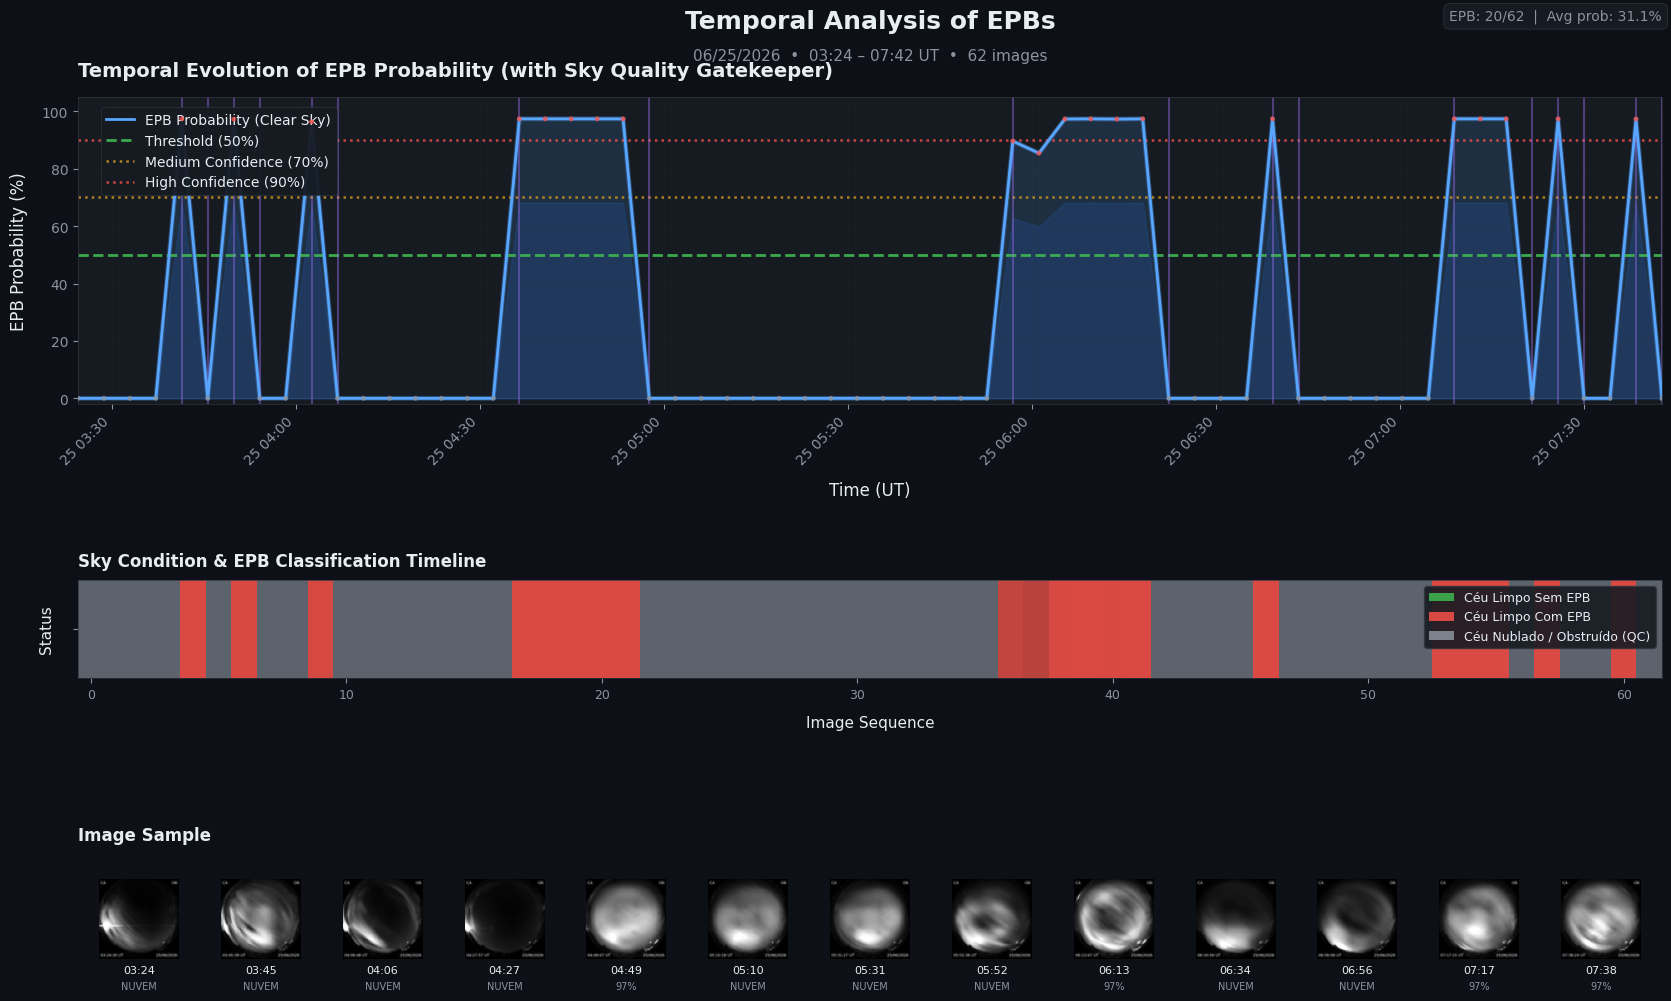


✅ TEMPORAL ANALYSIS COMPLETED


In [8]:
# ========== 5. ANÁLISE TEMPORAL (NOITE NUBLADA — DEMONSTRAÇÃO DO QC) ==========
CLOUDY_NIGHT_FOLDER = 'util/CA_20260624/processed'

print(f"☁️ Processando sequência temporal nublada: {CLOUDY_NIGHT_FOLDER}")
df_cloudy_night = analyze_temporal_sequence(
    system=system,
    image_folder=CLOUDY_NIGHT_FOLDER,
    target_size=target_size,
    show_thumbnails=True,
    thumbnail_interval=5,
    use_qc=True
)

In [9]:
# ========== 6. ANÁLISE DE PERÍODOS CRÍTICOS ==========
if df_epb_night is not None and not df_epb_night.empty:
    analyze_critical_periods(df_epb_night)

🔍 CRITICAL PERIODS ANALYSIS
📅 Date: 10/22/2025 | Period: 21:14 - 07:08 UT

🔄 DETECTED TRANSITIONS
----------------------------------------------------------------------
   Moments where the model changed classification:

   1. 21:18:24 UT | No EPB → WITH EPB 🔴 | Prob: 81.5%

⚡ EPB EVENT START ANALYSIS
----------------------------------------------------------------------
   First EPB detection: 21:18:24 UT

   Analysis window: 21:03 - 21:33 UT
   Images in window: 5

   Details:
   ------------------------------------------------------------
   21:14:10 UT | 🟢   0.0% | Céu Nublado (QC)
   21:18:24 UT | 🟠  81.5% | EPB ◄── TRANSITION
   21:22:38 UT | 🟠  88.1% | EPB
   21:26:51 UT | 🔴  90.8% | EPB
   21:31:05 UT | 🔴  93.5% | EPB
   ------------------------------------------------------------

   📊 Pre-transition statistics (last 5 images):
      • Average probability: 0.0%
      • Maximum probability: 0.0%

📈 OVERALL NIGHT STATISTICS
-------------------------------------------------------